Little 10 min: (60745, 3) 5 min: (2870, 3)
Middle 10 min: (60745, 3) 5 min: (2870, 3)
Ring 10 min: (60745, 3) 5 min: (2870, 3)
Index 10 min: (60745, 3) 5 min: (2870, 3)
Thumb 10 min: (60745, 3) 5 min: (2870, 3)

Dataset Information
Features: (31805, 40)
Labels: (31805,)
Features per batch: 40

Finger Distribution
Little    6361
Middle    6361
Ring      6361
Index     6361
Thumb     6361
Name: count, dtype: int64

Session Distribution
10min    30370
5min      1435
Name: count, dtype: int64

Training: (19083, 40)
Testing: (12722, 40)

Random Test Batch
Finger: Ring
Batch index: 7595

Reading | EMG1 | EMG2
      1 |    71 |     0
      2 |    82 |    10
      3 |    30 |     0
      4 |     0 |     9
      5 |     5 |     2
      6 |    15 |    49
      7 |    17 |     4
      8 |    38 |     0
      9 |     0 |     9
     10 |     0 |    23

Statistical Features
Statistic                          EMG1           EMG2
Mean                            25.8000        10.6000
Median           

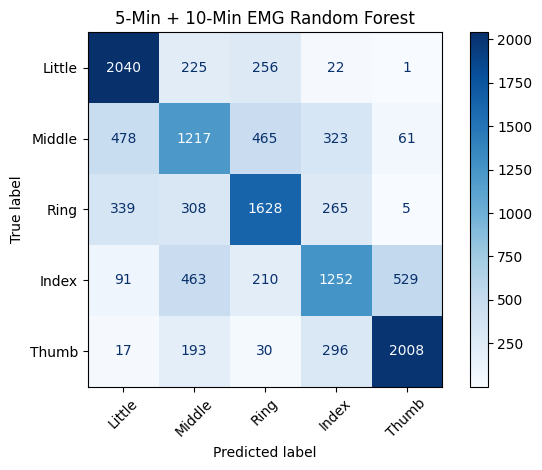


Random Batch Prediction
Actual: Ring
Predicted: Ring
CORRECT

Top 20 Most Important Features
                 Feature  Importance
             EMG1_Median    0.078102
               EMG1_Mean    0.074612
EMG1_Mean_Absolute_Value    0.070228
                EMG1_RMS    0.048865
 EMG1_Standard_Deviation    0.040673
    EMG1_Waveform_Length    0.040582
           EMG1_Variance    0.038729
              EMG1_Range    0.033951
            EMG1_Maximum    0.033420
              Raw_EMG1_4    0.025474
                EMG2_RMS    0.025320
EMG2_Mean_Absolute_Value    0.024744
               EMG2_Mean    0.024731
              Raw_EMG1_9    0.024249
    EMG2_Waveform_Length    0.024196
             Raw_EMG1_10    0.022834
 EMG2_Standard_Deviation    0.022170
              Raw_EMG1_7    0.021808
              Raw_EMG1_3    0.021712
              Raw_EMG1_2    0.021528


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


little_10min = pd.read_csv(
    "../EMG Recordings/little_finger 10mins.csv"
)

middle_10min = pd.read_csv(
    "../EMG Recordings/middle_finger_10mins.csv"
)

ring_10min = pd.read_csv(
    "../EMG Recordings/ring_finger_10mins.csv"
)

index_10min = pd.read_csv(
    "../EMG Recordings/index_finger_10mins.csv"
)

thumb_10min = pd.read_csv(
    "../EMG Recordings/thumb_finger_10mins.csv"
)


index_5min = pd.read_csv(
    "../EMG Recordings/index emg_2sensor_20260922_124922.csv"
)

middle_5min = pd.read_csv(
    "../EMG Recordings/middle finger emg_2sensor_20260922_124337.csv"
)

ring_5min = pd.read_csv(
    "../EMG Recordings/Ring finger emg_2sensor_20260922_123712.csv"
)

little_5min = pd.read_csv(
    "../EMG Recordings/little finger emg_2sensor_20260922_123054.csv"
)

thumb_5min = pd.read_csv(
    "../EMG Recordings/Thumb finger emg_2sensor_20260922_125701.csv"
)


recordings_10min = {
    "Little": little_10min.head(60745),
    "Middle": middle_10min.head(60745),
    "Ring": ring_10min.head(60745),
    "Index": index_10min.head(60745),
    "Thumb": thumb_10min.head(60745)
}


recordings_5min = {
    "Little": little_5min.head(2870),
    "Middle": middle_5min.head(2870),
    "Ring": ring_5min.head(2870),
    "Index": index_5min.head(2870),
    "Thumb": thumb_5min.head(2870)
}


for finger in recordings_10min:

    print(
        finger,
        "10 min:",
        recordings_10min[finger].shape,
        "5 min:",
        recordings_5min[finger].shape
    )


def calculate_statistics(values):

    values = values.astype(float)

    mean_value = np.mean(values)
    median_value = np.median(values)
    minimum_value = np.min(values)
    maximum_value = np.max(values)
    standard_deviation = np.std(values)
    variance_value = np.var(values)
    value_range = maximum_value - minimum_value
    rms_value = np.sqrt(np.mean(values ** 2))
    mean_absolute_value = np.mean(np.abs(values))
    waveform_length = np.sum(np.abs(np.diff(values)))

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]


def create_batches(data, batch_size=10):

    signals = data[
        ["emg1", "emg2"]
    ].values

    batches = []

    for i in range(
        0,
        len(signals),
        batch_size
    ):

        batch = signals[
            i:i + batch_size
        ]

        if len(batch) == batch_size:

            raw_features = batch.flatten()

            emg1_statistics = calculate_statistics(
                batch[:, 0]
            )

            emg2_statistics = calculate_statistics(
                batch[:, 1]
            )

            combined_features = np.concatenate(
                [
                    raw_features,
                    emg1_statistics,
                    emg2_statistics
                ]
            )

            batches.append(
                combined_features
            )

    return np.array(
        batches
    )


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]


feature_names = []


for reading in range(1, 11):

    feature_names.append(
        f"Raw_EMG1_{reading}"
    )

    feature_names.append(
        f"Raw_EMG2_{reading}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


emg_features = []

finger_labels = []

session_labels = []


for finger in recordings_10min:

    batches_10min = create_batches(
        recordings_10min[finger]
    )

    batches_5min = create_batches(
        recordings_5min[finger]
    )


    for batch in batches_10min:

        emg_features.append(
            batch
        )

        finger_labels.append(
            finger
        )

        session_labels.append(
            "10min"
        )


    for batch in batches_5min:

        emg_features.append(
            batch
        )

        finger_labels.append(
            finger
        )

        session_labels.append(
            "5min"
        )


emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)


print("\nDataset Information")

print(
    "Features:",
    emg_features.shape
)

print(
    "Labels:",
    finger_labels.shape
)

print(
    "Features per batch:",
    emg_features.shape[1]
)


print("\nFinger Distribution")

print(
    pd.Series(
        finger_labels
    ).value_counts()
)


print("\nSession Distribution")

print(
    pd.Series(
        session_labels
    ).value_counts()
)


(
    train_features,
    test_features,
    train_labels,
    test_labels

) = train_test_split(

    emg_features,
    finger_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    stratify=finger_labels
)


print(
    "\nTraining:",
    train_features.shape
)

print(
    "Testing:",
    test_features.shape
)


scaler = StandardScaler()


train_features_scaled = scaler.fit_transform(
    train_features
)


test_features_scaled = scaler.transform(
    test_features
)


random_index = np.random.randint(
    0,
    len(test_features)
)


random_raw_features = test_features[
    random_index
]


random_scaled_features = test_features_scaled[
    random_index
]


random_label = test_labels[
    random_index
]


raw_signal = random_raw_features[
    :20
].reshape(
    10,
    2
)


print("\nRandom Test Batch")

print(
    "Finger:",
    random_label
)


print(
    "Batch index:",
    random_index
)


print("\nReading | EMG1 | EMG2")


for i in range(10):

    print(
        f"{i + 1:>7} | "
        f"{raw_signal[i, 0]:>5.0f} | "
        f"{raw_signal[i, 1]:>5.0f}"
    )


emg1_stats = random_raw_features[
    20:30
]


emg2_stats = random_raw_features[
    30:40
]


print("\nStatistical Features")


print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{emg1_stats[i]:>15.4f}"
        f"{emg2_stats[i]:>15.4f}"
    )


scaled_emg1_stats = random_scaled_features[
    20:30
]


scaled_emg2_stats = random_scaled_features[
    30:40
]


print("\nScaled Statistical Features")


print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{scaled_emg1_stats[i]:>15.4f}"
        f"{scaled_emg2_stats[i]:>15.4f}"
    )


model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)


model.fit(
    train_features_scaled,
    train_labels
)


predicted_fingers = model.predict(
    test_features_scaled
)


accuracy = accuracy_score(
    test_labels,
    predicted_fingers
)


correct_predictions = np.sum(
    test_labels == predicted_fingers
)


print("\nRandom Forest Results")


print(
    "Correct predictions:",
    correct_predictions
)


print(
    "Total predictions:",
    len(test_labels)
)


print(
    f"Accuracy: {accuracy * 100:.4f}%"
)


print(
    "\nClassification Report:\n"
)


print(
    classification_report(
        test_labels,
        predicted_fingers,
        digits=4,
        zero_division=0
    )
)


finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    predicted_fingers,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    "5-Min + 10-Min EMG Random Forest"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()

plt.show()


random_prediction = model.predict(
    random_scaled_features.reshape(
        1,
        -1
    )
)


print("\nRandom Batch Prediction")


print(
    "Actual:",
    random_label
)


print(
    "Predicted:",
    random_prediction[0]
)


if random_prediction[0] == random_label:

    print("CORRECT")

else:

    print("INCORRECT")


feature_importance = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": model.feature_importances_
    }
)


feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)


print("\nTop 20 Most Important Features")


print(
    feature_importance.head(20).to_string(
        index=False
    )
)